## Preprocessing

In [1]:
import pandas as pd
import numpy as np
import os, sys
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv('D:\CreditCard\improved_synthetic_fraud_transactions.csv')

In [3]:
data.head()

,transaction_id,timestamp,customer_id,amount,merchant_category,transaction_type,payment_method,channel,card_present,country,customer_age,account_age_days,transactions_last_24h,avg_amount_30d,amount_to_customer_avg,distance_from_home_km,device_trust_score,failed_attempts_last_24h,merchant_risk_score,is_fraud
0,T00079021,2026-01-02 07:30:00,C014273,117.80,travel,purchase,credit_card,mobile_app,0,IN,60.0,651.0,3,36.55,3.223,8.67,0.816,0,0.544,0
1,T00032575,2026-03-13 12:56:00,C002487,26.49,grocery,purchase,digital_wallet,mobile_app,0,NG,33.0,604.0,1,69.27,0.382,14.02,0.889,0,0.214,0
2,T00005688,2026-02-02 04:44:00,C013512,194.21,electronics,purchase,digital_wallet,mobile_app,0,US,19.0,2349.0,2,126.39,1.537,6.51,0.831,0,0.279,0
3,T00046165,2026-06-19 16:16:00,C012286,46.21,grocery,purchase,debit_card,contactless,1,GB,47.0,414.0,1,81.72,0.565,13.72,0.792,0,0.045,0
4,T00060105,2026-01-22 12:03:00,C003223,40.48,utilities,recurring_payment,credit_card,in_store,1,US,43.0,473.0,3,75.96,0.533,4.94,0.885,1,0.212,0


In [4]:
data['customer_id'].nunique()

17938

In [5]:
data['transaction_id'].nunique()

100000

In [6]:
data = data.drop(columns = 'transaction_id')

In [7]:
data['timestamp'] = pd.to_datetime(data['timestamp'])

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[ns]
 1   customer_id               100000 non-null  object        
 2   amount                    100000 non-null  float64       
 3   merchant_category         100000 non-null  object        
 4   transaction_type          100000 non-null  object        
 5   payment_method            100000 non-null  object        
 6   channel                   100000 non-null  object        
 7   card_present              100000 non-null  int64         
 8   country                   100000 non-null  object        
 9   customer_age              98800 non-null   float64       
 10  account_age_days          100000 non-null  float64       
 11  transactions_last_24h     100000 non-null  int64         
 12  avg

In [9]:
data['customer_id'] = data['customer_id'].str.replace('C', '', regex = False).astype('int')

In [10]:
data['customer_id'].nunique()

17938

In [11]:
data.isnull().sum()/len(data)*100

timestamp                   0.000
customer_id                 0.000
amount                      0.000
merchant_category           0.000
transaction_type            0.000
payment_method              0.000
channel                     0.000
card_present                0.000
country                     0.000
customer_age                1.200
account_age_days            0.000
transactions_last_24h       0.000
avg_amount_30d              0.000
amount_to_customer_avg      0.000
distance_from_home_km       0.567
device_trust_score          1.714
failed_attempts_last_24h    0.000
merchant_risk_score         0.793
is_fraud                    0.000
dtype: float64

In [12]:
data.dtypes

timestamp                   datetime64[ns]
customer_id                          int64
amount                             float64
merchant_category                   object
transaction_type                    object
payment_method                      object
channel                             object
card_present                         int64
country                             object
customer_age                       float64
account_age_days                   float64
transactions_last_24h                int64
avg_amount_30d                     float64
amount_to_customer_avg             float64
distance_from_home_km              float64
device_trust_score                 float64
failed_attempts_last_24h             int64
merchant_risk_score                float64
is_fraud                             int64
dtype: object

In [13]:
data.duplicated().sum()

np.int64(0)

In [14]:
y = data['is_fraud']
x = data.drop(columns=['is_fraud', 'customer_id'])


In [15]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
                            x, y, test_size= 0.2, random_state = 101, stratify = y)


In [16]:
from sklearn.preprocessing import OneHotEncoder
cat_cols = ['merchant_category','transaction_type','payment_method','channel','country']
encoder = OneHotEncoder(sparse_output= False, handle_unknown= 'ignore')
train_encoded = encoder.fit_transform(x_train[cat_cols])
test_encoded = encoder.transform(x_test[cat_cols])

In [17]:
train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoder.get_feature_names_out(),
    index=x_train.index
).astype('int64')

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoder.get_feature_names_out(),
    index=x_test.index
).astype('int64')

x_train = x_train.drop(columns=cat_cols)
x_test = x_test.drop(columns=cat_cols)

x_train = pd.concat([x_train, train_encoded_df], axis=1)
x_test = pd.concat([x_test, test_encoded_df], axis=1)


In [18]:
x_train.head()

,timestamp,amount,card_present,customer_age,account_age_days,transactions_last_24h,avg_amount_30d,amount_to_customer_avg,distance_from_home_km,device_trust_score,...,country_BR,country_CA,country_DE,country_FR,country_GB,country_IN,country_NG,country_SG,country_TR,country_US
83046,2026-05-13 23:58:00,690.59,1,50.0,500.0,2,138.11,5.000,23.01,0.733,...,0,0,0,0,0,0,0,0,0,1
74705,2026-01-24 01:19:00,16.16,1,40.0,1534.0,4,42.92,0.377,1.86,0.785,...,0,0,0,0,1,0,0,0,0,0
81648,2026-03-08 12:57:00,52.84,0,51.0,2210.0,4,143.85,0.367,4.63,0.771,...,0,0,1,0,0,0,0,0,0,0
85382,2026-05-24 23:34:00,33.29,0,48.0,1490.0,2,69.68,0.478,7.26,0.921,...,0,0,0,0,0,0,0,0,0,1
20567,2026-06-04 07:33:00,43.84,0,40.0,300.0,1,35.70,1.228,2.41,0.685,...,0,0,0,0,0,0,0,0,0,1


In [19]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
cols = ['customer_age', 'distance_from_home_km', 'device_trust_score', 'merchant_risk_score']
x_train[cols] = imputer.fit_transform(x_train[cols])
x_test[cols] = imputer.transform(x_test[cols])

In [20]:
x_train['hour'] = x_train['timestamp'].dt.hour
x_train['day_of_week'] = x_train['timestamp'].dt.day_of_week
x_train['is_weekend'] = (x_train['timestamp'].dt.day_of_week>=5).astype(int)

x_test['hour'] = x_test['timestamp'].dt.hour
x_test['day_of_week'] = x_test['timestamp'].dt.day_of_week
x_test['is_weekend'] = (x_test['timestamp'].dt.day_of_week>=5).astype(int)

x_train = x_train.drop(columns = 'timestamp')
x_test = x_test.drop(columns = 'timestamp')

In [21]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 80000 entries, 83046 to 12968
Data columns (total 51 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   amount                              80000 non-null  float64
 1   card_present                        80000 non-null  int64  
 2   customer_age                        80000 non-null  float64
 3   account_age_days                    80000 non-null  float64
 4   transactions_last_24h               80000 non-null  int64  
 5   avg_amount_30d                      80000 non-null  float64
 6   amount_to_customer_avg              80000 non-null  float64
 7   distance_from_home_km               80000 non-null  float64
 8   device_trust_score                  80000 non-null  float64
 9   failed_attempts_last_24h            80000 non-null  int64  
 10  merchant_risk_score                 80000 non-null  float64
 11  merchant_category_cash_advance      80000 

In [22]:
x_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 72791 to 65526
Data columns (total 51 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   amount                              20000 non-null  float64
 1   card_present                        20000 non-null  int64  
 2   customer_age                        20000 non-null  float64
 3   account_age_days                    20000 non-null  float64
 4   transactions_last_24h               20000 non-null  int64  
 5   avg_amount_30d                      20000 non-null  float64
 6   amount_to_customer_avg              20000 non-null  float64
 7   distance_from_home_km               20000 non-null  float64
 8   device_trust_score                  20000 non-null  float64
 9   failed_attempts_last_24h            20000 non-null  int64  
 10  merchant_risk_score                 20000 non-null  float64
 11  merchant_category_cash_advance      20000 

In [23]:
from sklearn.preprocessing import StandardScaler
num_cols = x_train.select_dtypes(include = ['int64', 'float64', 'int32']).columns
sc = StandardScaler()
x_train[num_cols] = sc.fit_transform(x_train[num_cols])
x_test[num_cols] = sc.transform(x_test[num_cols])


In [24]:
x_train.head()

,amount,card_present,customer_age,account_age_days,transactions_last_24h,avg_amount_30d,amount_to_customer_avg,distance_from_home_km,device_trust_score,failed_attempts_last_24h,...,country_FR,country_GB,country_IN,country_NG,country_SG,country_TR,country_US,hour,day_of_week,is_weekend
83046,3.137580,1.662687,0.862552,-0.653343,-0.470355,0.563221,2.821676,-0.033693,-0.036542,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,1.240839,1.659803,-0.501136,-0.633266
74705,-0.481933,1.662687,0.053825,0.096922,0.674375,-0.587624,-0.589629,-0.244914,0.356735,-0.521999,...,-0.234562,2.674407,-0.334813,-0.216187,-0.071773,-0.070977,-0.805906,-1.515500,0.997177,1.579114
81648,-0.285080,-0.601436,0.943425,0.587425,0.674375,0.632618,-0.597008,-0.217250,0.250853,3.192638,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,-0.805906,0.072152,1.496615,1.579114
85382,-0.390000,-0.601436,0.700807,0.064996,-0.470355,-0.264096,-0.515101,-0.190985,1.385305,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,1.240839,1.659803,1.496615,1.579114
20567,-0.333381,-0.601436,0.053825,-0.798462,-1.042720,-0.674913,0.038323,-0.239421,-0.399566,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,1.240839,-0.649508,-0.001698,-0.633266


In [25]:
x_test.head()

,amount,card_present,customer_age,account_age_days,transactions_last_24h,avg_amount_30d,amount_to_customer_avg,distance_from_home_km,device_trust_score,failed_attempts_last_24h,...,country_FR,country_GB,country_IN,country_NG,country_SG,country_TR,country_US,hour,day_of_week,is_weekend
72791,-0.531683,-0.601436,-0.754903,-0.513303,-0.470355,-0.872826,-0.605125,-0.201771,1.392868,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,-0.805906,-0.793840,-0.001698,-0.633266
36621,-0.250357,-0.601436,-0.754903,-0.432036,1.246740,2.209997,-0.708431,0.138180,1.052532,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,1.240839,0.938143,0.997177,1.579114
32795,2.287859,-0.601436,-1.725376,-0.841998,-0.470355,4.559080,-0.029564,-0.146544,-0.755028,-0.521999,...,-0.234562,2.674407,-0.334813,-0.216187,-0.071773,-0.070977,-0.805906,0.216483,1.496615,1.579114
1759,-0.440394,1.662687,-1.078394,-0.833291,0.674375,-0.522217,-0.502557,-0.187789,0.954213,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,1.240839,-1.515500,0.997177,1.579114
2453,-0.504474,-0.601436,-0.350539,3.325820,-1.615086,-0.270383,-0.740160,-0.155731,0.893709,-0.521999,...,-0.234562,-0.373915,-0.334813,-0.216187,-0.071773,-0.070977,-0.805906,1.515471,0.997177,1.579114


## Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight= 'balanced', max_iter = 1000, random_state=42)

In [27]:
x_subtrain, x_subtest, y_subtrain, y_subtest = train_test_split(
    x_train, y_train, test_size = 0.2, stratify=y_train, random_state = 101)


In [28]:
x_train.shape

(80000, 51)

In [29]:
x_subtrain.shape

(64000, 51)

In [30]:
y_subtrain.shape

(64000,)

In [31]:
int(y_subtrain.sum())

960

In [32]:
model.fit(x_subtrain, y_subtrain)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [33]:
y_proba = model.predict_proba(x_subtest)[:,1]

In [34]:
y_sub_pred = model.predict(x_subtest)

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score
print(classification_report(y_subtest,y_sub_pred, digits = 4))
print(confusion_matrix(y_subtest, y_sub_pred))
print(average_precision_score(y_subtest, y_proba))

              precision    recall  f1-score   support

           0     0.9988    0.9098    0.9522     15760
           1     0.1356    0.9292    0.2366       240

    accuracy                         0.9101     16000
   macro avg     0.5672    0.9195    0.5944     16000
weighted avg     0.9859    0.9101    0.9415     16000

[[14338  1422]
 [   17   223]]
0.3773427557441747


In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]

results = []

for i in thresholds:
    y_proba_value = (y_proba>=i).astype(int)
    
    results.append({
        "Threshold": i,
        "Precision": precision_score(y_subtest, y_proba_value, zero_division=0),
        "Recall": recall_score(y_subtest, y_proba_value, zero_division=0),
        "F1-score": f1_score(y_subtest, y_proba_value, zero_division=0),
        "False Positives": int(((y_subtest == 0) & (y_proba_value == 1)).sum()),
        "Missed Fraud": int(((y_subtest == 1) & (y_proba_value == 0)).sum())
    })


In [37]:
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  False Positives  Missed Fraud
      0.10     0.0572  0.9917    0.1081             3924             2
      0.20     0.0799  0.9917    0.1479             2740             2
      0.30     0.0994  0.9833    0.1805             2139             4
      0.40     0.1174  0.9542    0.2090             1722            11
      0.50     0.1356  0.9292    0.2366             1422            17
      0.60     0.1536  0.8917    0.2621             1179            26
      0.70     0.1804  0.8458    0.2974              922            37
      0.80     0.2237  0.7875    0.3484              656            51
      0.90     0.2887  0.6833    0.4059              404            76
      0.95     0.3496  0.5667    0.4324              253           104


In [38]:
y_test_proba = model.predict_proba(x_test)[:,1]
best_thresh = 0.95
y_test_pred = (y_test_proba>=best_thresh).astype(int)

In [39]:
print(classification_report(y_test, y_test_pred, digits = 4))
print(confusion_matrix(y_test, y_test_pred))
print(average_precision_score(y_test, y_test_proba))

              precision    recall  f1-score   support

           0     0.9931    0.9842    0.9886     19700
           1     0.3459    0.5500    0.4247       300

    accuracy                         0.9777     20000
   macro avg     0.6695    0.7671    0.7067     20000
weighted avg     0.9834    0.9777    0.9801     20000

[[19388   312]
 [  135   165]]
0.3881274284369808


## Random Forest

In [40]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators = 300,
    class_weight = 'balanced',
    random_state = 101,
    n_jobs = -1
)


In [41]:
rf_model.fit(x_subtrain, y_subtrain)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
y_sub_pred_rf = rf_model.predict(x_subtest)
y_sub_proba_rf = rf_model.predict_proba(x_subtest)[:,1]

In [43]:
print("Classification Report:")
print(classification_report(y_subtest, y_sub_pred_rf, digits= 4))

print("Confusion Matrix:")
print(confusion_matrix(y_subtest, y_sub_pred_rf))

print("Average Precision: ")
print(average_precision_score(y_subtest, y_sub_proba_rf))

Classification Report:
              precision    recall  f1-score   support

           0     0.9856    0.9999    0.9927     15760
           1     0.8333    0.0417    0.0794       240

    accuracy                         0.9855     16000
   macro avg     0.9095    0.5208    0.5360     16000
weighted avg     0.9833    0.9855    0.9790     16000

Confusion Matrix:
[[15758     2]
 [  230    10]]
Average Precision: 
0.47054340269535216


In [44]:
thr = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
results = []

for i in thresholds:
    y_proba_value_rf = (y_sub_proba_rf>=i).astype(int)
    
    results.append({
        "Threshold": i,
        "Precision": precision_score(y_subtest, y_proba_value_rf, zero_division=0),
        "Recall": recall_score(y_subtest, y_proba_value_rf, zero_division=0),
        "F1-score": f1_score(y_subtest, y_proba_value_rf, zero_division=0),
        "False Positives": int(((y_subtest == 0) & (y_proba_value_rf == 1)).sum()),
        "Missed Fraud": int(((y_subtest == 1) & (y_proba_value_rf == 0)).sum())
    })

In [45]:
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  False Positives  Missed Fraud
      0.10     0.2954  0.6917    0.4140              396            74
      0.20     0.4783  0.4125    0.4430              108           141
      0.30     0.6667  0.2583    0.3724               31           178
      0.40     0.8372  0.1500    0.2544                7           204
      0.50     0.8333  0.0417    0.0794                2           230
      0.60     0.6667  0.0083    0.0165                1           238
      0.70     1.0000  0.0042    0.0083                0           239
      0.80     0.0000  0.0000    0.0000                0           240
      0.90     0.0000  0.0000    0.0000                0           240
      0.95     0.0000  0.0000    0.0000                0           240


In [46]:
y_test_proba_rf = rf_model.predict_proba(x_test)[:,1]
best_thresh = 0.20
y_test_pred_rf = (y_test_proba_rf>=best_thresh).astype(int)

In [47]:
print(classification_report(y_test, y_test_pred_rf, digits = 4))
print(confusion_matrix(y_test, y_test_pred_rf))
print(average_precision_score(y_test, y_test_proba_rf))

              precision    recall  f1-score   support

           0     0.9912    0.9926    0.9919     19700
           1     0.4669    0.4233    0.4441       300

    accuracy                         0.9841     20000
   macro avg     0.7291    0.7080    0.7180     20000
weighted avg     0.9834    0.9841    0.9837     20000

[[19555   145]
 [  173   127]]
0.4173881732152075


In [48]:
from sklearn.metrics import average_precision_score

rf_val_proba = rf_model.predict_proba(x_subtest)[:, 1]
rf_test_proba = rf_model.predict_proba(x_test)[:, 1]

print("Validation AP:",
      average_precision_score(y_subtest, rf_val_proba))

print("Test AP:",
      average_precision_score(y_test, rf_test_proba))

Validation AP: 0.47054340269535216
Test AP: 0.4173881732152075


## XGBoost


In [49]:
from xgboost import XGBClassifier

In [50]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Legitimate transactions:", negative_count)
print("Fraudulent transactions:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Legitimate transactions: 78800
Fraudulent transactions: 1200
Scale Pos Weight: 65.66666666666667


In [51]:
xgb_model = XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,

    max_depth=4,
    min_child_weight=3,
    gamma=0,

    subsample=0.8,
    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight,

    reg_alpha=0,
    reg_lambda=1,

    objective='binary:logistic',
    eval_metric='aucpr',

    tree_method='hist',
    random_state=101,
    n_jobs=-1,

    early_stopping_rounds=50
)

In [52]:
xgb_model.fit(
    x_subtrain,
    y_subtrain,

    eval_set=[(x_subtest, y_subtest)],

    verbose=100
)


[0]	validation_0-aucpr:0.12407
[100]	validation_0-aucpr:0.52939
[200]	validation_0-aucpr:0.53483
[201]	validation_0-aucpr:0.53508


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,50
,enable_categorical,True
,eval_metric,'aucpr'


In [53]:
print("Best iteration:", xgb_model.best_iteration)

print("Best validation score:", xgb_model.best_score)

Best iteration: 151
Best validation score: 0.5406985671896941


In [54]:
y_val_proba_xgb = xgb_model.predict_proba(x_subtest)[:, 1]

In [55]:
y_val_pred_xgb = (
    y_val_proba_xgb >= 0.50
).astype(int)

In [56]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

In [57]:
print("Classification Report:")
print(classification_report(
    y_subtest,
    y_val_pred_xgb,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_subtest, y_val_pred_xgb))

print("Average Precision:",
      average_precision_score(y_subtest, y_val_proba_xgb))

print("ROC-AUC:",
      roc_auc_score(y_subtest, y_val_proba_xgb))

Classification Report:
              precision    recall  f1-score   support

           0     0.9988    0.9241    0.9600     15760
           1     0.1572    0.9292    0.2688       240

    accuracy                         0.9242     16000
   macro avg     0.5780    0.9266    0.6144     16000
weighted avg     0.9862    0.9242    0.9497     16000

Confusion Matrix:
[[14564  1196]
 [   17   223]]
Average Precision: 0.5415306911445968
ROC-AUC: 0.9786077622673435


In [58]:
thresholds = [
    0.10, 0.20, 0.30, 0.40, 0.50,
    0.60, 0.70, 0.80, 0.90, 0.95
]

results_xgb = []

for threshold in thresholds:

    y_pred = (
        y_val_proba_xgb >= threshold
    ).astype(int)

    precision = precision_score(
        y_subtest, y_pred, zero_division=0
    )

    recall = recall_score(
        y_subtest, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_subtest, y_pred, zero_division=0
    )

    cm = confusion_matrix(y_subtest, y_pred)

    fp = cm[0, 1]
    missed_fraud = cm[1, 0]

    results_xgb.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'False Positives': fp,
        'Missed Fraud': missed_fraud
    })

xgb_results_df = pd.DataFrame(results_xgb)

print(xgb_results_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  False Positives  Missed Fraud
      0.10     0.0657  0.9958    0.1232             3401             1
      0.20     0.0920  0.9958    0.1685             2358             1
      0.30     0.1106  0.9708    0.1986             1874             7
      0.40     0.1317  0.9542    0.2314             1510            11
      0.50     0.1572  0.9292    0.2688             1196            17
      0.60     0.1854  0.8917    0.3070              940            26
      0.70     0.2281  0.8375    0.3586              680            39
      0.80     0.3002  0.7667    0.4314              429            56
      0.90     0.4389  0.5833    0.5009              179           100
      0.95     0.6040  0.3750    0.4627               59           150


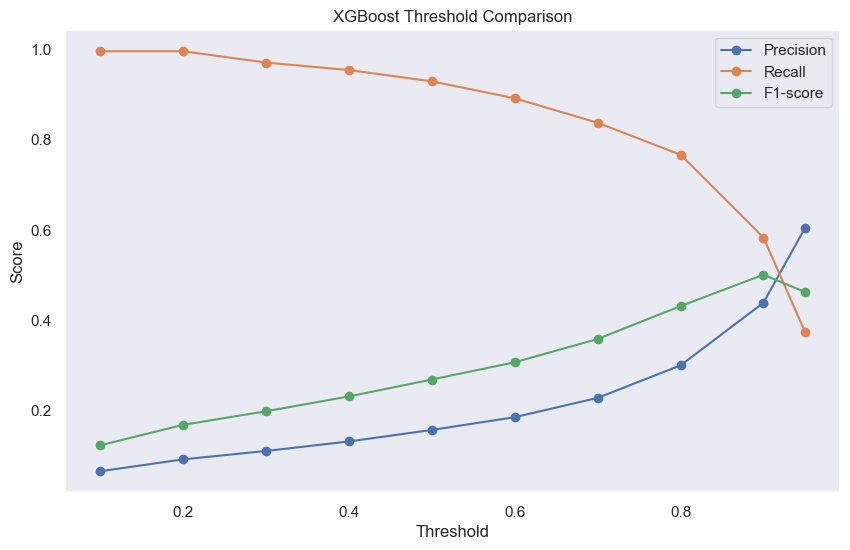

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    xgb_results_df['Threshold'],
    xgb_results_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    xgb_results_df['Threshold'],
    xgb_results_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    xgb_results_df['Threshold'],
    xgb_results_df['F1-score'],
    marker='o',
    label='F1-score'
)

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('XGBoost Threshold Comparison')

plt.legend()
plt.grid()
plt.show()

In [60]:
y_test_proba_xgb = xgb_model.predict_proba(x_test)[:, 1]

In [61]:
best_threshold_xgb = 0.80

In [62]:
y_test_pred_xgb = (
    y_test_proba_xgb >= best_threshold_xgb
).astype(int)

In [63]:
print("XGBoost - Final Test Results")

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred_xgb,
    digits=4
))

print("\nConfusion Matrix:")

print(confusion_matrix(
    y_test,
    y_test_pred_xgb
))

print("\nAverage Precision:",
      average_precision_score(y_test, y_test_proba_xgb))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_proba_xgb))

XGBoost - Final Test Results

Classification Report:
              precision    recall  f1-score   support

           0     0.9962    0.9733    0.9846     19700
           1     0.3015    0.7567    0.4311       300

    accuracy                         0.9700     20000
   macro avg     0.6488    0.8650    0.7079     20000
weighted avg     0.9858    0.9700    0.9763     20000


Confusion Matrix:
[[19174   526]
 [   73   227]]

Average Precision: 0.486959528748768
ROC-AUC: 0.9767301184433164


In [64]:
importance = pd.DataFrame({
    'Feature': x_subtrain.columns,
    'Importance': xgb_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.head(15))

                               Feature  Importance
9             failed_attempts_last_24h    0.168607
11      merchant_category_cash_advance    0.144371
6               amount_to_customer_avg    0.091385
25           transaction_type_purchase    0.048431
13       merchant_category_electronics    0.044553
10                 merchant_risk_score    0.038691
7                distance_from_home_km    0.034982
1                         card_present    0.029575
8                   device_trust_score    0.029175
12     merchant_category_digital_goods    0.026816
0                               amount    0.019765
4                transactions_last_24h    0.016725
26  transaction_type_recurring_payment    0.016479
31       payment_method_digital_wallet    0.012999
3                     account_age_days    0.011949


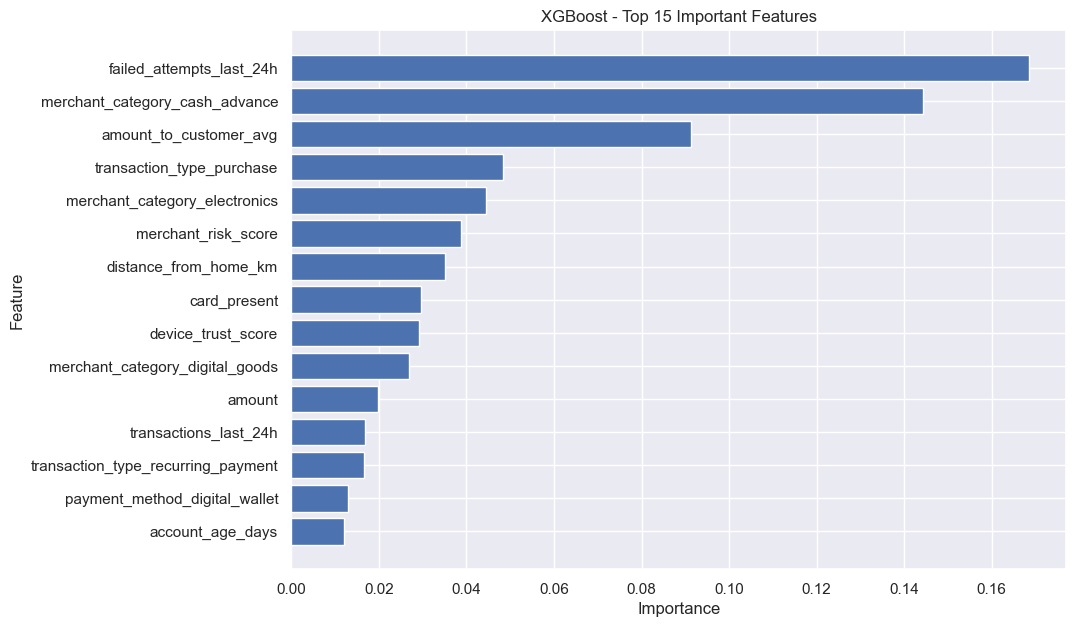

In [65]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance['Feature'].head(15)[::-1],
    importance['Importance'].head(15)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("XGBoost - Top 15 Important Features")

plt.show()

## Cross-Validation Models

In [66]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import pandas as pd

In [67]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=101
)

In [68]:
# Logistic Regression
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)


# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=101,
    n_jobs=-1
)


# XGBoost
xgb_cv_model = XGBClassifier(
    n_estimators=xgb_model.best_iteration + 1,
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=3,
    gamma=0,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    reg_alpha=0,
    reg_lambda=1,
    objective='binary:logistic',
    eval_metric='aucpr',
    tree_method='hist',
    random_state=101,
    n_jobs=-1
)

In [69]:
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'XGBoost': xgb_cv_model
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring='average_precision',
        n_jobs=1
    )

    cv_results.append({
        'Model': name,
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4],
        'Mean AP': scores.mean(),
        'Standard Deviation': scores.std()
    })

results_df = pd.DataFrame(cv_results)

print(results_df.round(4).to_string(index=False))

              Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean AP  Standard Deviation
Logistic Regression  0.3630  0.4205  0.4018  0.3866  0.4037   0.3951              0.0193
      Random Forest  0.3704  0.4135  0.4821  0.4208  0.4202   0.4214              0.0356
            XGBoost  0.4552  0.5145  0.4879  0.4541  0.5308   0.4885              0.0308


## SHAP

In [70]:
!pip install shap


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [71]:
import shap
import matplotlib.pyplot as plt

# Use a sample of validation data
X_shap = x_subtest.sample(
    n=min(500, len(x_subtest)),
    random_state=101
)

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer(X_shap)

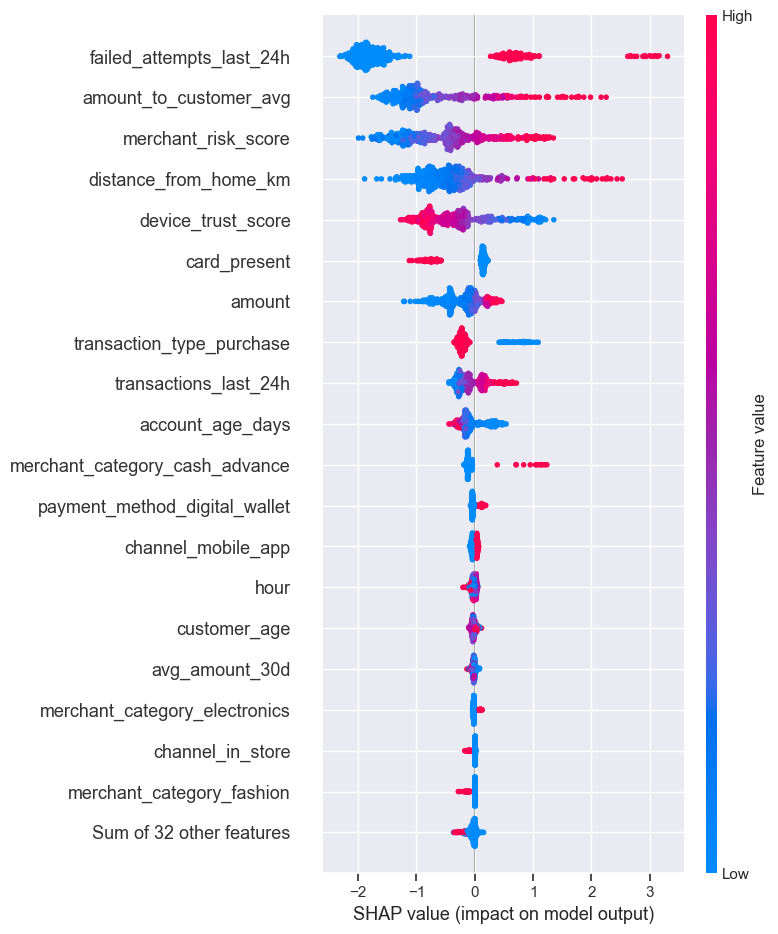

In [72]:
shap.plots.beeswarm(
    shap_values,
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()